# **Amanda - Mini Project (26 Sep 2026)**

1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd


from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

2. Import datasets

In [ ]:
pop = pd.read_csv(
    'ResidentPopulationbyPlanningAreaSubzoneofResidenceAgeGroupandSexCensusofPopulation2020.csv'
)

subzones = gpd.read_file(
    'MasterPlan2019SubzoneBoundaryNoSeaGEOJSON.geojson'
)

wifi = gpd.read_file('WirelessHotSpotsGEOJSON.geojson')

cc = gpd.read_file('CommunityClubs.geojson')

libraries = gpd.read_file('Libraries.geojson')


3. Clean and merge datasets

3.1 Population Data

In [ ]:
pop.head()
print(pop.shape)
pop.info()

(388, 61)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 388 entries, 0 to 387
Data columns (total 61 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Number             388 non-null    object
 1   Total_Total        388 non-null    object
 2   Total_0_4          388 non-null    object
 3   Total_5_9          388 non-null    object
 4   Total_10_14        388 non-null    object
 5   Total_15_19        388 non-null    object
 6   Total_20_24        388 non-null    object
 7   Total_25_29        388 non-null    object
 8   Total_30_34        388 non-null    object
 9   Total_35_39        388 non-null    object
 10  Total_40_44        388 non-null    object
 11  Total_45_49        388 non-null    object
 12  Total_50_54        388 non-null    object
 13  Total_55_59        388 non-null    object
 14  Total_60_64        388 non-null    object
 15  Total_65_69        388 non-null    object
 16  Total_70_74        388 non-null   

In [ ]:
# Check for duplicate rows
print("Population duplicate rows:", pop.duplicated().sum())

Population duplicate rows: 0


In [ ]:
#Rename the first population column
pop = pop.rename(columns={'Number': 'area'})

In [ ]:
#Convert the population columns to numeric. Exclude first column because 'areas' contains text

population_columns = pop.columns[1:]

#If value cannot be converted to numeric replace it with NaN

for col in population_columns:
    pop[col] = pd.to_numeric(pop[col], errors='coerce')

In [ ]:
#Check for missing values
pop.isnull().sum().sort_values(ascending=False).head(20)

,0
Males_90andOver,167
Males_85_89,155
Females_90andOver,154
Females_85_89,150
Males_80_84,144
Total_90andOver,142
Total_85_89,141
Females_80_84,140
Females_75_79,138
Males_75_79,138


In [ ]:
#Calculate the pop aged 65 and above, and create new columns 'senior_65_plus' and 'senior_percentage'
senior_columns = [
    'Total_65_69',
    'Total_70_74',
    'Total_75_79',
    'Total_80_84',
    'Total_85_89',
    'Total_90andOver'
]

pop['senior_65_plus'] = pop[senior_columns].sum(axis=1, min_count=1)

pop['senior_percentage'] = (
    pop['senior_65_plus'] / pop['Total_Total'] * 100
)

In [ ]:
#Only keep columns we need

pop_clean = pop[
    [
        'area',
        'Total_Total',
        'senior_65_plus',
        'senior_percentage'
    ]
].copy()

pop_clean.head()

,area,Total_Total,senior_65_plus,senior_percentage
0,Total,4044210.0,614380.0,15.191595
1,Ang Mo Kio - Total,162280.0,35220.0,21.703229
2,Ang Mo Kio Town Centre,4810.0,780.0,16.216216
3,Cheng San,28070.0,6030.0,21.482009
4,Chong Boon,26500.0,6440.0,24.301887


In [ ]:
#Rename Total_Total to total_population' for ease of understanding

pop_clean = pop_clean.rename(
    columns={'Total_Total': 'total_population'}
)

pop_clean.head()

,area,total_population,senior_65_plus,senior_percentage
0,Total,4044210.0,614380.0,15.191595
1,Ang Mo Kio - Total,162280.0,35220.0,21.703229
2,Ang Mo Kio Town Centre,4810.0,780.0,16.216216
3,Cheng San,28070.0,6030.0,21.482009
4,Chong Boon,26500.0,6440.0,24.301887


In [ ]:
# Remove aggregate rows as we are analysing individual subzones

pop_clean = pop_clean[
    ~pop_clean['area'].str.contains('- Total', na=False)
].copy()

pop_clean = pop_clean[
    pop_clean['area'] != 'Total'
].copy()

pop_clean = pop_clean.reset_index(drop=True)

In [ ]:
#Check on the dataset

print(pop_clean.shape)
pop_clean.head(10)

(332, 4)


,area,total_population,senior_65_plus,senior_percentage
0,Ang Mo Kio Town Centre,4810.0,780.0,16.216216
1,Cheng San,28070.0,6030.0,21.482009
2,Chong Boon,26500.0,6440.0,24.301887
3,Kebun Bahru,22620.0,5080.0,22.458002
4,Sembawang Hills,6850.0,1320.0,19.270073
5,Shangri-La,15960.0,3570.0,22.368421
6,Tagore,7950.0,1510.0,18.993711
7,Townsville,21140.0,5060.0,23.935667
8,Yio Chu Kang,20.0,NaN,NaN
9,Yio Chu Kang East,4200.0,720.0,17.142857


In [ ]:
#Sanity check

pop_clean.describe()

,total_population,senior_65_plus,senior_percentage
count,286.000000,232.000000,232.000000
mean,14141.048951,2650.431034,16.748961
std,18422.573785,2770.775562,7.834218
min,10.000000,10.000000,1.562500
25%,380.000000,537.500000,11.663692
50%,7880.000000,2000.000000,16.571347
75%,22162.500000,3737.500000,20.318809
max,130980.000000,20200.000000,86.363636


In [ ]:
#Quick check on subzones with highest senior percentages
pop_clean.sort_values(
    'senior_percentage',
    ascending=False
).head(10)

,area,total_population,senior_65_plus,senior_percentage
180,Loyang West,220.0,190.0,86.363636
121,Lakeside (Leisure),1070.0,410.0,38.317757
176,Pearl's Hill,6120.0,2080.0,33.986928
225,Kampong Glam,120.0,40.0,33.333333
174,China Square,1430.0,460.0,32.167832
138,Crawford,8380.0,2620.0,31.264916
264,Boat Quay,130.0,40.0,30.769231
232,Victoria,1760.0,540.0,30.681818
230,Selegie,210.0,60.0,28.571429
44,Kampong Tiong Bahru,9010.0,2540.0,28.190899


3.2 Subzone Boundary Data

In [ ]:
subzones.head()

,OBJECTID,SUBZONE_NO,SUBZONE_N,SUBZONE_C,CA_IND,PLN_AREA_N,PLN_AREA_C,REGION_N,REGION_C,INC_CRC,FMEL_UPD_D,SHAPE.AREA,SHAPE.LEN,geometry
0,676,12,DEPOT ROAD,BMSZ12,N,BUKIT MERAH,BM,CENTRAL REGION,CR,C22DED671DE2A940,20191223152313,442297.509556,4281.667289,"POLYGON ((103.81454 1.28239, 103.81427 1.28253..."
1,677,2,BUKIT MERAH,BMSZ02,N,BUKIT MERAH,BM,CENTRAL REGION,CR,085EF219A5A1AEAD,20191223152313,411722.830243,3074.963234,"POLYGON ((103.82209 1.28049, 103.82209 1.28057..."
2,678,3,CHINATOWN,OTSZ03,Y,OUTRAM,OT,CENTRAL REGION,CR,EF2B9A91AF49E025,20191223152313,587222.679344,4297.599898,"POLYGON ((103.84375 1.28508, 103.84363 1.28518..."
3,679,4,PHILLIP,DTSZ04,Y,DOWNTOWN CORE,DT,CENTRAL REGION,CR,615D4EDDEF809F8E,20191223152313,39437.935270,871.554888,"POLYGON ((103.84962 1.28412, 103.84963 1.28414..."
4,680,5,RAFFLES PLACE,DTSZ05,Y,DOWNTOWN CORE,DT,CENTRAL REGION,CR,72107B11807074F4,20191223152313,188767.489706,1872.752161,"POLYGON ((103.85253 1.28617, 103.85236 1.28651..."


In [ ]:
subzones.columns


Index(['OBJECTID', 'SUBZONE_NO', 'SUBZONE_N', 'SUBZONE_C', 'CA_IND',
       'PLN_AREA_N', 'PLN_AREA_C', 'REGION_N', 'REGION_C', 'INC_CRC',
       'FMEL_UPD_D', 'SHAPE.AREA', 'SHAPE.LEN', 'geometry'],
      dtype='object')

In [ ]:
subzones.shape

(332, 14)

In [ ]:
# Check for duplicate subzones
print(
    "Duplicate subzone names:",
    subzones['SUBZONE_N'].duplicated().sum()
)

Duplicate subzone names: 0


In [ ]:
#Simplify GeoDataFrame

subzones = subzones[
    ['SUBZONE_N', 'PLN_AREA_N', 'REGION_N', 'geometry']
].copy()

subzones.head()

,SUBZONE_N,PLN_AREA_N,REGION_N,geometry
0,DEPOT ROAD,BUKIT MERAH,CENTRAL REGION,"POLYGON ((103.81454 1.28239, 103.81427 1.28253..."
1,BUKIT MERAH,BUKIT MERAH,CENTRAL REGION,"POLYGON ((103.82209 1.28049, 103.82209 1.28057..."
2,CHINATOWN,OUTRAM,CENTRAL REGION,"POLYGON ((103.84375 1.28508, 103.84363 1.28518..."
3,PHILLIP,DOWNTOWN CORE,CENTRAL REGION,"POLYGON ((103.84962 1.28412, 103.84963 1.28414..."
4,RAFFLES PLACE,DOWNTOWN CORE,CENTRAL REGION,"POLYGON ((103.85253 1.28617, 103.85236 1.28651..."


In [ ]:
#Rename the columns to clearer names
subzones = subzones.rename(columns={
    'SUBZONE_N': 'subzone',
    'PLN_AREA_N': 'planning_area',
    'REGION_N': 'region'
})

In [ ]:
# Standardise subzone names for matching

subzones['subzone_key'] = (
    subzones['subzone']
    .str.strip()
    .str.upper()
)

pop_clean['subzone_key'] = (
    pop_clean['area']
    .str.strip()
    .str.upper()
)

In [ ]:
#Check whether the subzone names match
matched = pop_clean['subzone_key'].isin(
    subzones['subzone_key']
)

print('Matched:', matched.sum())
print('Not matched:', (~matched).sum())

Matched: 332
Not matched: 0


4. Data Integration and Feature Engineering

4.1 Merge Population Data with Subzone Boundaries

In [ ]:
#Merge 2 datasets, keep every geographical subzone, whether or not population info exists
pop_geo = subzones.merge(
    pop_clean,
    on='subzone_key',
    how='left'
)

pop_geo.head()

,subzone,planning_area,region,geometry,subzone_key,area,total_population,senior_65_plus,senior_percentage
0,DEPOT ROAD,BUKIT MERAH,CENTRAL REGION,"POLYGON ((103.81454 1.28239, 103.81427 1.28253...",DEPOT ROAD,Depot Road,6540.0,1060.0,16.207951
1,BUKIT MERAH,BUKIT MERAH,CENTRAL REGION,"POLYGON ((103.82209 1.28049, 103.82209 1.28057...",BUKIT MERAH,Bukit Merah,1110.0,270.0,24.324324
2,CHINATOWN,OUTRAM,CENTRAL REGION,"POLYGON ((103.84375 1.28508, 103.84363 1.28518...",CHINATOWN,Chinatown,10490.0,2090.0,19.923737
3,PHILLIP,DOWNTOWN CORE,CENTRAL REGION,"POLYGON ((103.84962 1.28412, 103.84963 1.28414...",PHILLIP,Phillip,10.0,NaN,NaN
4,RAFFLES PLACE,DOWNTOWN CORE,CENTRAL REGION,"POLYGON ((103.85253 1.28617, 103.85236 1.28651...",RAFFLES PLACE,Raffles Place,40.0,NaN,NaN


4.2 Wireless@SG Hotspot Accessibility

In [ ]:
print("WiFi dataset shape:", wifi.shape)
print("WiFi CRS:", wifi.crs)
print("Subzone CRS:", pop_geo.crs)

WiFi dataset shape: (1800, 3)
WiFi CRS: EPSG:4326
Subzone CRS: EPSG:4326


In [ ]:
# Check for duplicate WiFi records
print("WiFi duplicate rows:", wifi.duplicated().sum())

WiFi duplicate rows: 0


In [ ]:
#spatial join datasets
wifi_joined = gpd.sjoin(
    wifi,
    pop_geo[['subzone', 'geometry']],
    how='left',
    predicate='within'
)

In [ ]:
print("Total WiFi hotspots:", len(wifi_joined))
print("Matched to subzone:", wifi_joined['subzone'].notna().sum())
print("Not matched:", wifi_joined['subzone'].isna().sum())

Total WiFi hotspots: 1800
Matched to subzone: 1799
Not matched: 1


In [ ]:
wifi_count = (
    wifi_joined
    .dropna(subset=['subzone'])
    .groupby('subzone')
    .size()
    .reset_index(name='wifi_count')
)

wifi_count.head()

,subzone,wifi_count
0,ADMIRALTY,3
1,ALEXANDRA HILL,12
2,ALEXANDRA NORTH,1
3,ALJUNIED,23
4,ANAK BUKIT,6


In [ ]:
#Merge datasets
pop_geo = pop_geo.merge(
    wifi_count,
    on='subzone',
    how='left'
)

In [ ]:
#Replace missing WiFi counts with zero, change Nan to O
pop_geo['wifi_count'] = (
    pop_geo['wifi_count']
    .fillna(0)
    .astype(int)
)

In [ ]:
#check dataset
pop_geo[
    ['subzone',
     'total_population',
     'senior_65_plus',
     'senior_percentage',
     'wifi_count']
].head(10)

,subzone,total_population,senior_65_plus,senior_percentage,wifi_count
0,DEPOT ROAD,6540.0,1060.0,16.207951,3
1,BUKIT MERAH,1110.0,270.0,24.324324,36
2,CHINATOWN,10490.0,2090.0,19.923737,11
3,PHILLIP,10.0,NaN,NaN,0
4,RAFFLES PLACE,40.0,NaN,NaN,8
5,CHINA SQUARE,1430.0,460.0,32.167832,5
6,TIONG BAHRU,12890.0,2600.0,20.170675,6
7,BAYFRONT SUBZONE,NaN,NaN,NaN,3
8,TIONG BAHRU STATION,15120.0,2820.0,18.650794,5
9,CLIFFORD PIER,NaN,NaN,NaN,0


In [ ]:
#Verify total WiFi hotspots
print("Total WiFi hotspots counted:", pop_geo['wifi_count'].sum())

Total WiFi hotspots counted: 1799


4.3 Community Club Accesibility

In [ ]:
print("CC dataset shape:", cc.shape)
print("CC CRS:", cc.crs)

CC dataset shape: (125, 3)
CC CRS: EPSG:4326


In [ ]:
#Check that the CRS matches
print("Subzone CRS:", pop_geo.crs)

Subzone CRS: EPSG:4326


In [ ]:
# Check for duplicate Community Club records
print("CC duplicate rows:", cc.duplicated().sum())

CC duplicate rows: 0


In [ ]:
#Spatial join, match cc to a subzone if the cc point lies within that subzone polygon
cc_joined = gpd.sjoin(
    cc,
    pop_geo[['subzone', 'geometry']],
    how='left',
    predicate='within'
)

In [ ]:
#Check match
print("Total Community Clubs:", len(cc_joined))
print("Matched to subzone:", cc_joined['subzone'].notna().sum())
print("Not matched:", cc_joined['subzone'].isna().sum())

Total Community Clubs: 125
Matched to subzone: 125
Not matched: 0


In [ ]:
#Count Community Clubs by subzone
cc_count = (
    cc_joined
    .dropna(subset=['subzone'])
    .groupby('subzone')
    .size()
    .reset_index(name='cc_count')
)

cc_count.head()

,subzone,cc_count
0,ADMIRALTY,1
1,ALEXANDRA HILL,1
2,ALJUNIED,1
3,ANAK BUKIT,1
4,ANCHORVALE,1


In [ ]:
#Merge into pop_geo
pop_geo = pop_geo.merge(
    cc_count,
    on='subzone',
    how='left'
)

In [ ]:
#Replace missing values with 0
pop_geo['cc_count'] = (
    pop_geo['cc_count']
    .fillna(0)
    .astype(int)
)

In [ ]:
#Check merged datasets

pop_geo[
    ['subzone',
     'senior_65_plus',
     'senior_percentage',
     'wifi_count',
     'cc_count']
].head(10)

,subzone,senior_65_plus,senior_percentage,wifi_count,cc_count
0,DEPOT ROAD,1060.0,16.207951,3,0
1,BUKIT MERAH,270.0,24.324324,36,0
2,CHINATOWN,2090.0,19.923737,11,2
3,PHILLIP,NaN,NaN,0,0
4,RAFFLES PLACE,NaN,NaN,8,0
5,CHINA SQUARE,460.0,32.167832,5,0
6,TIONG BAHRU,2600.0,20.170675,6,1
7,BAYFRONT SUBZONE,NaN,NaN,3,0
8,TIONG BAHRU STATION,2820.0,18.650794,5,0
9,CLIFFORD PIER,NaN,NaN,0,0


4.4 Library Accesibility

In [ ]:
print("Libraries dataset shape:", libraries.shape)
print("Libraries CRS:", libraries.crs)

Libraries dataset shape: (27, 3)
Libraries CRS: EPSG:4326


In [ ]:
# Check that the CRS matches
print("Subzone CRS:", pop_geo.crs)

Subzone CRS: EPSG:4326


In [ ]:
# Check for duplicate Library records
print("Library duplicate rows:", libraries.duplicated().sum())

Library duplicate rows: 0


In [ ]:
# Spatial join
library_joined = gpd.sjoin(
    libraries,
    pop_geo[['subzone', 'geometry']],
    how='left',
    predicate='within'
)

In [ ]:
# Check match
print("Total Libraries:", len(library_joined))
print("Matched to subzone:", library_joined['subzone'].notna().sum())
print("Not matched:", library_joined['subzone'].isna().sum())


Total Libraries: 27
Matched to subzone: 27
Not matched: 0


In [ ]:
# Count Libraries by subzone
library_count = (
    library_joined
    .dropna(subset=['subzone'])
    .groupby('subzone')
    .size()
    .reset_index(name='library_count')
)

library_count.head()

,subzone,library_count
0,ALJUNIED,1
1,ANG MO KIO TOWN CENTRE,1
2,BEDOK NORTH,1
3,BISHAN EAST,1
4,BUGIS,2


In [ ]:
# Merge into pop_geo
pop_geo = pop_geo.merge(
    library_count,
    on='subzone',
    how='left'
)

# Replace missing values with 0
pop_geo['library_count'] = (
    pop_geo['library_count']
    .fillna(0)
    .astype(int)
)

In [ ]:
#Check combined dataset
pop_geo[
    ['subzone',
     'senior_65_plus',
     'senior_percentage',
     'wifi_count',
     'cc_count',
     'library_count']
].head(10)

,subzone,senior_65_plus,senior_percentage,wifi_count,cc_count,library_count
0,DEPOT ROAD,1060.0,16.207951,3,0,0
1,BUKIT MERAH,270.0,24.324324,36,0,0
2,CHINATOWN,2090.0,19.923737,11,2,0
3,PHILLIP,NaN,NaN,0,0,0
4,RAFFLES PLACE,NaN,NaN,8,0,0
5,CHINA SQUARE,460.0,32.167832,5,0,1
6,TIONG BAHRU,2600.0,20.170675,6,1,0
7,BAYFRONT SUBZONE,NaN,NaN,3,0,0
8,TIONG BAHRU STATION,2820.0,18.650794,5,0,0
9,CLIFFORD PIER,NaN,NaN,0,0,0


In [ ]:
#Sanity check
print("Total Libraries counted:", pop_geo['library_count'].sum())

Total Libraries counted: 27


In [ ]:
#Sanity check
print("Total subzones:", len(pop_geo))

print(
    "Subzones with missing population:",
    pop_geo['total_population'].isna().sum()
)

print(
    "Subzones with 0 seniors:",
    (pop_geo['senior_65_plus'] == 0).sum()
)

Total subzones: 332
Subzones with missing population: 46
Subzones with 0 seniors: 0


In [ ]:
# Convert subzones to Singapore SVY21 coordinates
pop_geo_projected = pop_geo.to_crs(epsg=3414)

# Create centroid for each subzone
subzone_points = pop_geo_projected.copy()
subzone_points['geometry'] = subzone_points.geometry.centroid

In [ ]:
#Convert the other 3 facility datasets to the same projected CRS
wifi_projected = wifi.to_crs(epsg=3414)
cc_projected = cc.to_crs(epsg=3414)
libraries_projected = libraries.to_crs(epsg=3414)

In [ ]:
#Check everything is now using the same CRS
print(subzone_points.crs)
print(wifi_projected.crs)
print(cc_projected.crs)
print(libraries_projected.crs)

EPSG:3414
EPSG:3414
EPSG:3414
EPSG:3414


4.5 Distance-based accessibility features

In [ ]:
#Find nearest WIFI hotspot
nearest_wifi = gpd.sjoin_nearest(
    subzone_points[['subzone', 'geometry']],
    wifi_projected[['geometry']],
    how='left',
    distance_col='distance_to_nearest_wifi'
)

In [ ]:
#Remove those subzones which has more than 1 equally near WiFi hotspot
nearest_wifi = (
    nearest_wifi
    .sort_values('distance_to_nearest_wifi')
    .drop_duplicates(subset='subzone')
)

In [ ]:
#Merge distance into pop_geo
pop_geo = pop_geo.merge(
    nearest_wifi[['subzone', 'distance_to_nearest_wifi']],
    on='subzone',
    how='left'
)

In [ ]:
#nearest cc same as above
nearest_cc = gpd.sjoin_nearest(
    subzone_points[['subzone', 'geometry']],
    cc_projected[['geometry']],
    how='left',
    distance_col='distance_to_nearest_cc'
)

nearest_cc = (
    nearest_cc
    .sort_values('distance_to_nearest_cc')
    .drop_duplicates(subset='subzone')
)

pop_geo = pop_geo.merge(
    nearest_cc[['subzone', 'distance_to_nearest_cc']],
    on='subzone',
    how='left'
)

In [ ]:
#nearest library same as above
nearest_library = gpd.sjoin_nearest(
    subzone_points[['subzone', 'geometry']],
    libraries_projected[['geometry']],
    how='left',
    distance_col='distance_to_nearest_library'
)

nearest_library = (
    nearest_library
    .sort_values('distance_to_nearest_library')
    .drop_duplicates(subset='subzone')
)

pop_geo = pop_geo.merge(
    nearest_library[['subzone', 'distance_to_nearest_library']],
    on='subzone',
    how='left'
)

In [ ]:
#check if merged properly
print(pop_geo.columns.tolist())

['subzone', 'planning_area', 'region', 'geometry', 'subzone_key', 'area', 'total_population', 'senior_65_plus', 'senior_percentage', 'wifi_count', 'cc_count', 'library_count', 'distance_to_nearest_wifi', 'distance_to_nearest_cc', 'distance_to_nearest_library']


In [ ]:
#sanity check
pop_geo[
    ['distance_to_nearest_wifi',
     'distance_to_nearest_cc',
     'distance_to_nearest_library']
].describe()

,distance_to_nearest_wifi,distance_to_nearest_cc,distance_to_nearest_library
count,332.000000,332.000000,332.000000
mean,618.032629,1262.719657,1928.988547
std,1003.726384,1637.344824,1753.439752
min,15.749918,29.254222,111.071710
25%,126.590011,421.374140,930.943505
50%,305.994756,828.899679,1526.671829
75%,730.909450,1381.525294,2266.005285
max,10357.075695,12878.381862,13298.511093


4.6 Final Feature Selection

In [ ]:
#Define feature for clustering
cluster_features = [
    'senior_65_plus',
    'senior_percentage',
    'wifi_count',
    'cc_count',
    'library_count',
    'distance_to_nearest_wifi',
    'distance_to_nearest_cc',
    'distance_to_nearest_library'
]

In [ ]:
#Create model data, exclude subzones without seniors
model_data = pop_geo[
    pop_geo['senior_65_plus'] > 0
].copy()

model_data = model_data.reset_index(drop=True)

In [ ]:
#Check for missing values because PCS and K-Means cannot work with missing values
model_data[cluster_features].isnull().sum()

,0
senior_65_plus,0
senior_percentage,0
wifi_count,0
cc_count,0
library_count,0
distance_to_nearest_wifi,0
distance_to_nearest_cc,0
distance_to_nearest_library,0


In [ ]:
#Important to note for scaling later
model_data[cluster_features].describe()

,senior_65_plus,senior_percentage,wifi_count,cc_count,library_count,distance_to_nearest_wifi,distance_to_nearest_cc,distance_to_nearest_library
count,232.000000,232.000000,232.000000,232.000000,232.000000,232.000000,232.000000,232.000000
mean,2650.431034,16.748961,6.508621,0.530172,0.107759,355.742443,782.008489,1456.607428
std,2770.775562,7.834218,7.812185,0.683095,0.324378,435.445765,660.007338,894.955942
min,10.000000,1.562500,0.000000,0.000000,0.000000,15.749918,29.254222,111.071710
25%,537.500000,11.663692,1.000000,0.000000,0.000000,108.221013,332.596147,855.017806
50%,2000.000000,16.571347,5.000000,0.000000,0.000000,204.872170,650.610514,1289.960781
75%,3737.500000,20.318809,9.000000,1.000000,0.000000,432.082441,979.146490,1876.559429
max,20200.000000,86.363636,61.000000,4.000000,2.000000,3620.727028,4860.285317,5807.952177


5. Exploratory Data Analysis (EDA)

5.1 Senior population distribution

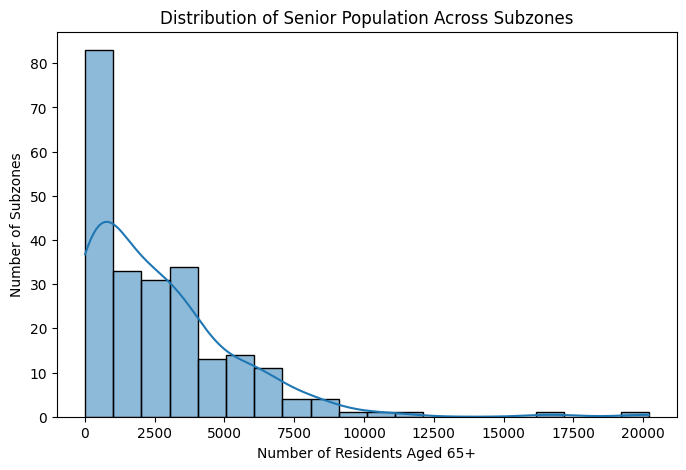

In [ ]:
#Senior population distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    model_data['senior_65_plus'],
    bins=20,
    kde=True
)

plt.title('Distribution of Senior Population Across Subzones')
plt.xlabel('Number of Residents Aged 65+')
plt.ylabel('Number of Subzones')

plt.show()

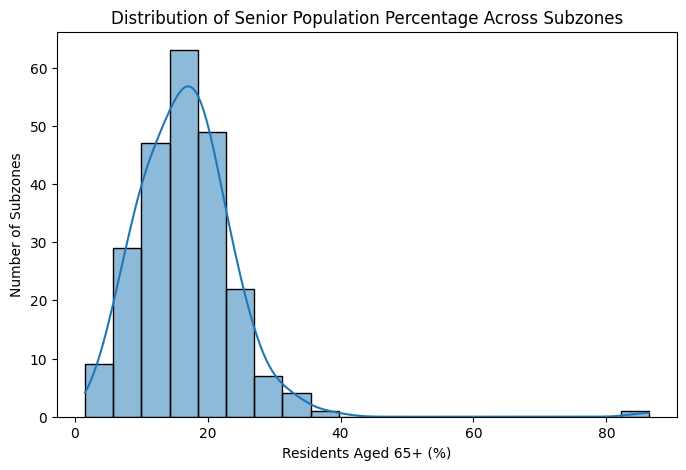

In [ ]:
#Senior percentage distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    model_data['senior_percentage'],
    bins=20,
    kde=True
)

plt.title('Distribution of Senior Population Percentage Across Subzones')
plt.xlabel('Residents Aged 65+ (%)')
plt.ylabel('Number of Subzones')

plt.show()

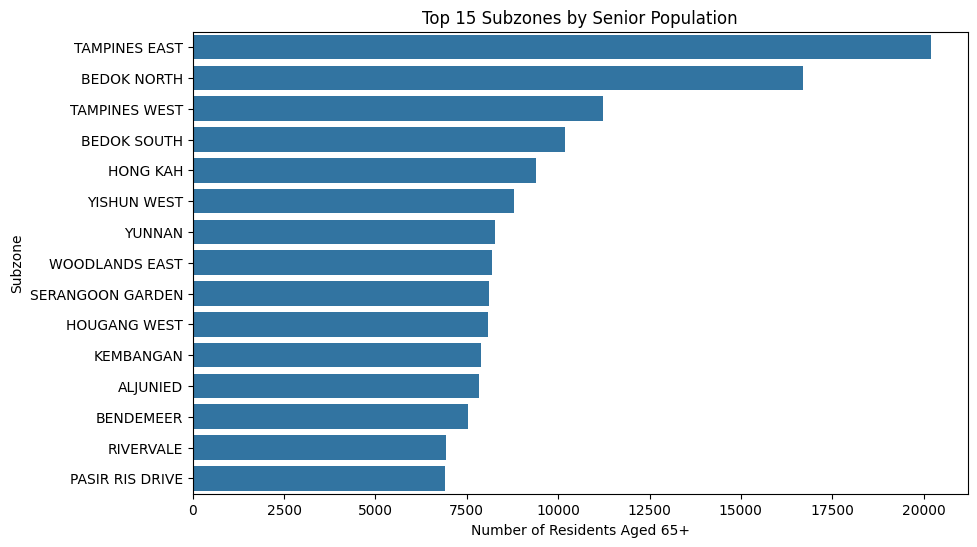

In [ ]:
#Top 15 subzones by senior population
top_senior_subzones = (
    model_data
    .sort_values('senior_65_plus', ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_senior_subzones,
    x='senior_65_plus',
    y='subzone'
)

plt.title('Top 15 Subzones by Senior Population')
plt.xlabel('Number of Residents Aged 65+')
plt.ylabel('Subzone')

plt.show()

5.2 Infrastructure Availability

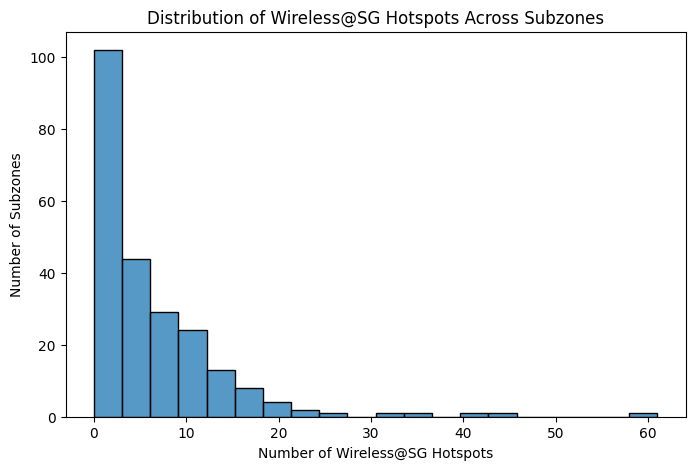

In [ ]:
#Distribution of infrastructure counts
plt.figure(figsize=(8, 5))

sns.histplot(
    model_data['wifi_count'],
    bins=20
)

plt.title('Distribution of Wireless@SG Hotspots Across Subzones')
plt.xlabel('Number of Wireless@SG Hotspots')
plt.ylabel('Number of Subzones')

plt.show()

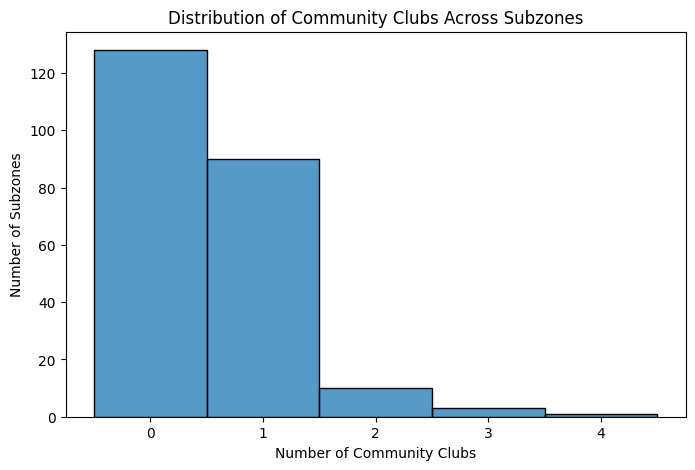

In [ ]:
#Distribution of CC
plt.figure(figsize=(8, 5))

sns.histplot(
    model_data['cc_count'],
    discrete=True
)

plt.title('Distribution of Community Clubs Across Subzones')
plt.xlabel('Number of Community Clubs')
plt.ylabel('Number of Subzones')

plt.show()

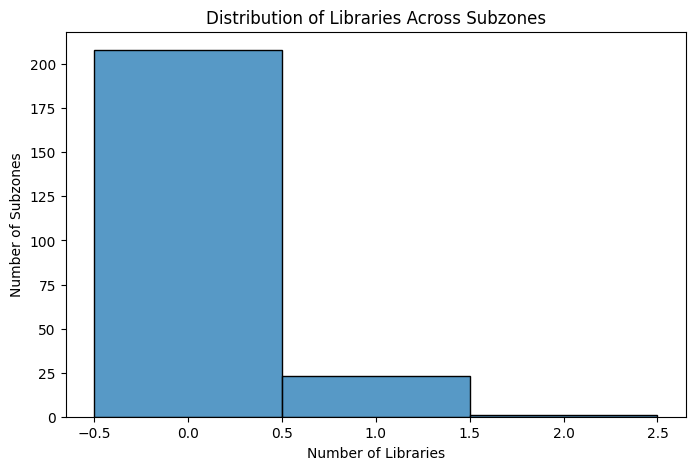

In [ ]:
#Distribution of libraries
plt.figure(figsize=(8, 5))

sns.histplot(
    model_data['library_count'],
    discrete=True
)

plt.title('Distribution of Libraries Across Subzones')
plt.xlabel('Number of Libraries')
plt.ylabel('Number of Subzones')

plt.show()

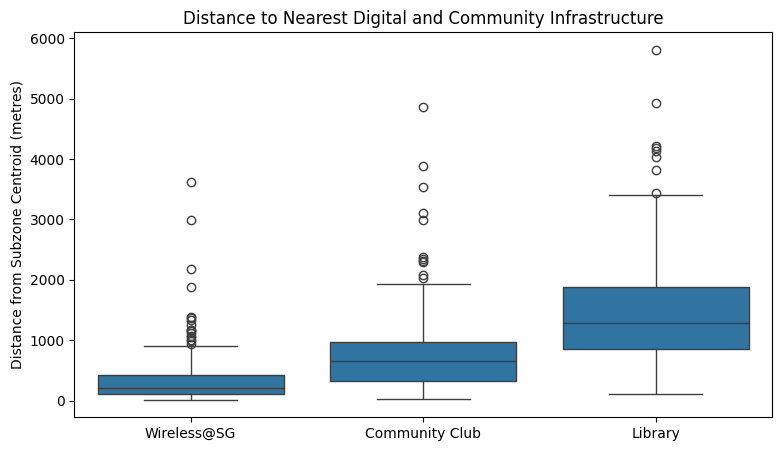

In [ ]:
#Distance to nearest infrastructure

distance_data = model_data[
    [
        'distance_to_nearest_wifi',
        'distance_to_nearest_cc',
        'distance_to_nearest_library'
    ]
].copy()

distance_data = distance_data.rename(columns={
    'distance_to_nearest_wifi': 'Wireless@SG',
    'distance_to_nearest_cc': 'Community Club',
    'distance_to_nearest_library': 'Library'
})

distance_long = distance_data.melt(
    var_name='Facility',
    value_name='Distance'
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=distance_long,
    x='Facility',
    y='Distance'
)

plt.title('Distance to Nearest Digital and Community Infrastructure')
plt.xlabel('')
plt.ylabel('Distance from Subzone Centroid (metres)')

plt.show()

5.3 Correlation Analysis

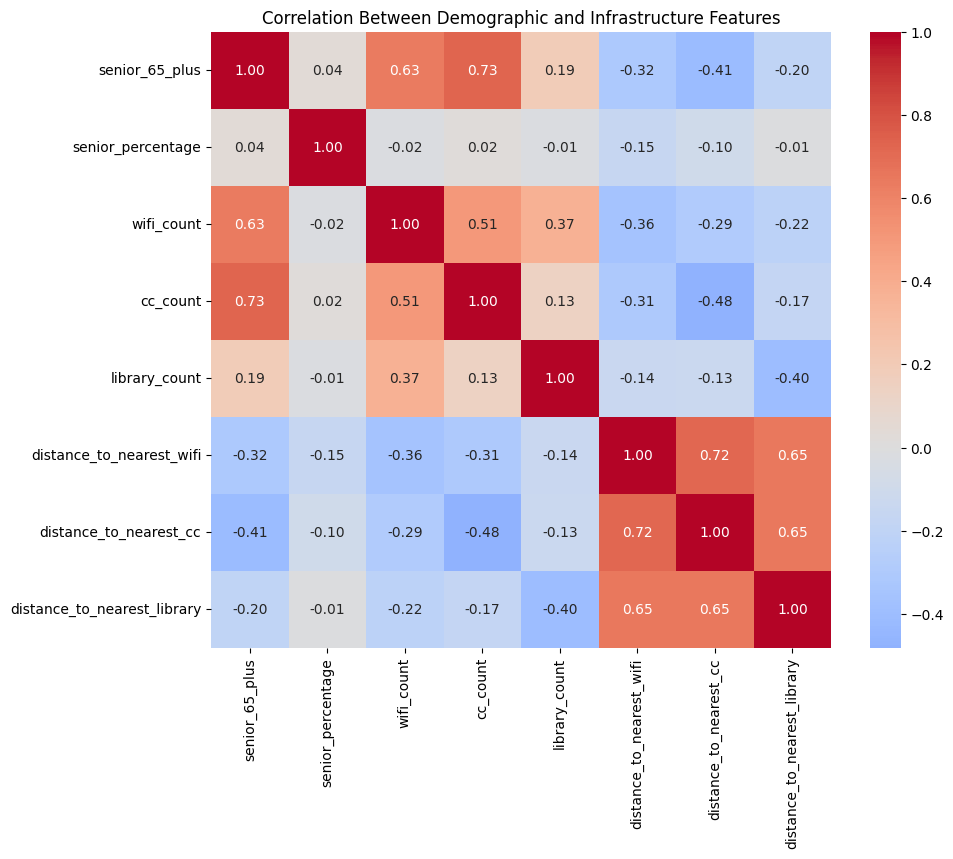

In [ ]:
#Correlation heatmap

plt.figure(figsize=(10, 8))

correlation_matrix = model_data[cluster_features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Between Demographic and Infrastructure Features')

plt.show()

5.4 Spatial Distribution of Senior Population

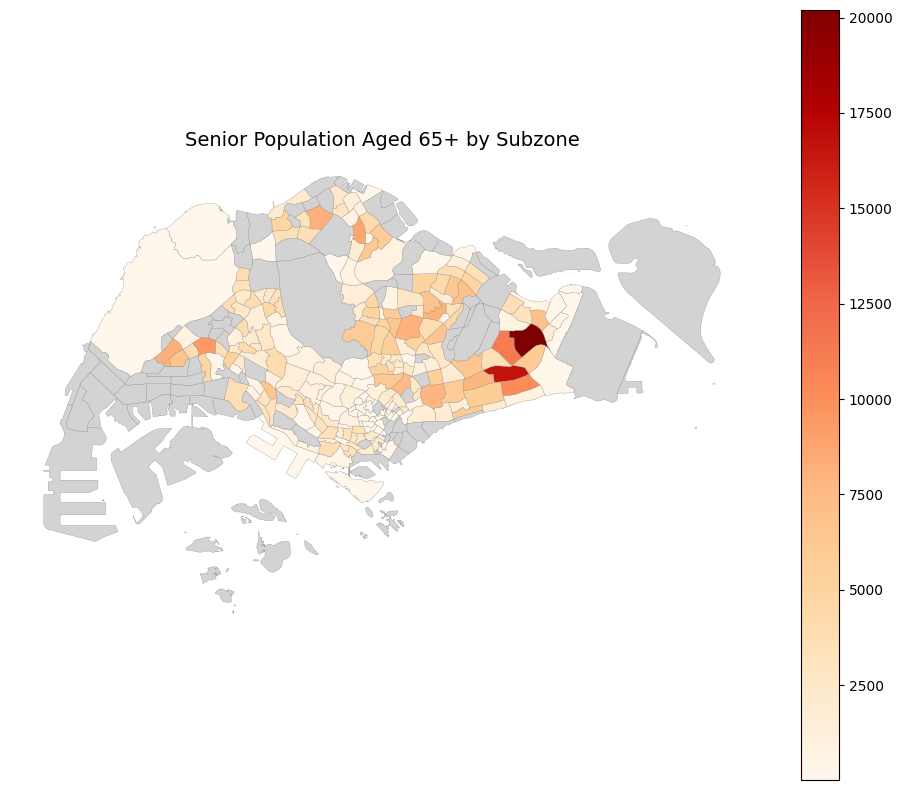

In [ ]:
#Senior population map

fig, ax = plt.subplots(figsize=(12, 10))

pop_geo.plot(
    column='senior_65_plus',
    cmap='OrRd',
    legend=True,
    ax=ax,
    edgecolor='grey',
    linewidth=0.2,
    missing_kwds={
        'color': 'lightgrey',
        'label': 'No population data'
    }
)

ax.set_title(
    'Senior Population Aged 65+ by Subzone',
    fontsize=14
)

ax.axis('off')

plt.show()


6. Feature Standardisation

In [ ]:
X = model_data[cluster_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
X_scaled[:5]

array([[-0.5752432 , -0.06920656, -0.45009265, -0.77781142, -0.33291929,
        -0.3492004 ,  0.05361785,  0.44560398],
       [-0.8609784 ,  0.96904921,  3.78321123, -0.77781142, -0.33291929,
        -0.6591114 , -0.47071486,  0.6409704 ],
       [-0.20270237,  0.40612102,  0.57616283,  2.15637149, -0.33291929,
        -0.57053751, -0.9525376 , -0.95750338],
       [-0.79225728,  1.97239973, -0.19352878, -0.77781142,  2.75657173,
        -0.46371168, -0.85412091, -1.36614684],
       [-0.01824041,  0.43770962, -0.06524685,  0.68928004, -0.33291929,
        -0.73148318, -1.07788701,  0.06620909]])

7. Principal Component Analysis (PCA)

In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [ ]:
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance):
    print(f"PC{i+1}: {variance:.4f}")

PC1: 0.4206
PC2: 0.1770
PC3: 0.1384
PC4: 0.1165
PC5: 0.0610
PC6: 0.0340
PC7: 0.0271
PC8: 0.0254


In [ ]:
cumulative_variance = np.cumsum(explained_variance)

for i, variance in enumerate(cumulative_variance):
    print(f"PC1 to PC{i+1}: {variance:.4f}")

PC1 to PC1: 0.4206
PC1 to PC2: 0.5976
PC1 to PC3: 0.7359
PC1 to PC4: 0.8524
PC1 to PC5: 0.9134
PC1 to PC6: 0.9474
PC1 to PC7: 0.9746
PC1 to PC8: 1.0000


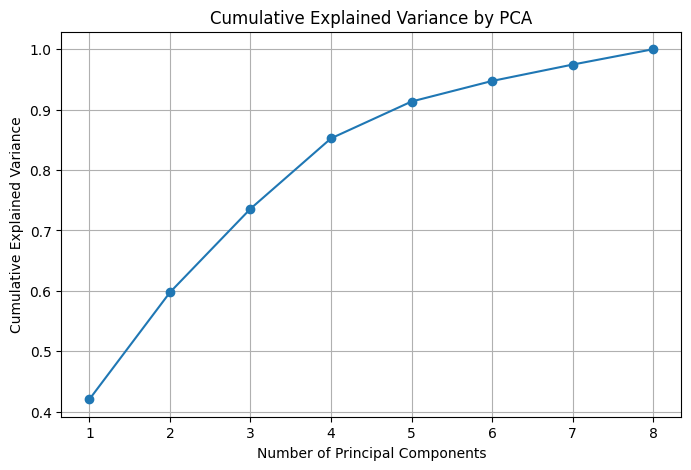

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by PCA')

plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid()

plt.show()

In [ ]:
pca_4 = PCA(n_components=4)

X_pca_4 = pca_4.fit_transform(X_scaled)

print("Shape before PCA:", X_scaled.shape)
print("Shape after PCA:", X_pca_4.shape)
print("Variance retained:", pca_4.explained_variance_ratio_.sum())

# Save first two principal components for visualisation
model_data['PC1'] = X_pca_4[:, 0]
model_data['PC2'] = X_pca_4[:, 1]

Shape before PCA: (232, 8)
Shape after PCA: (232, 4)
Variance retained: 0.8524387479795845


In [ ]:
model_data[
    ['subzone', 'PC1', 'PC2']
].head()

,subzone,PC1,PC2
0,DEPOT ROAD,0.823174,-0.621461
1,BUKIT MERAH,-0.986151,0.481303
2,CHINATOWN,-1.917411,-0.031115
3,CHINA SQUARE,-1.092075,-2.226717
4,TIONG BAHRU,-0.928413,-0.390401


In [ ]:
pca_loadings = pd.DataFrame(
    pca_4.components_.T,
    index=cluster_features,
    columns=['PC1', 'PC2', 'PC3', 'PC4']
)

pca_loadings.round(3)

,PC1,PC2,PC3,PC4
senior_65_plus,-0.402,0.442,-0.137,-0.002
senior_percentage,-0.051,-0.182,-0.567,0.792
wifi_count,-0.375,0.377,0.177,0.167
cc_count,-0.387,0.404,-0.220,-0.122
library_count,-0.224,-0.015,0.681,0.509
distance_to_nearest_wifi,0.411,0.380,0.141,0.111
distance_to_nearest_cc,0.436,0.293,0.189,0.235
distance_to_nearest_library,0.369,0.485,-0.246,0.057


8. K-Means Clustering

8.1 Selecting the number of clusters

8.1.1 Elbow calculation

In [ ]:
inertia = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_pca_4)
    inertia.append(kmeans.inertia_)

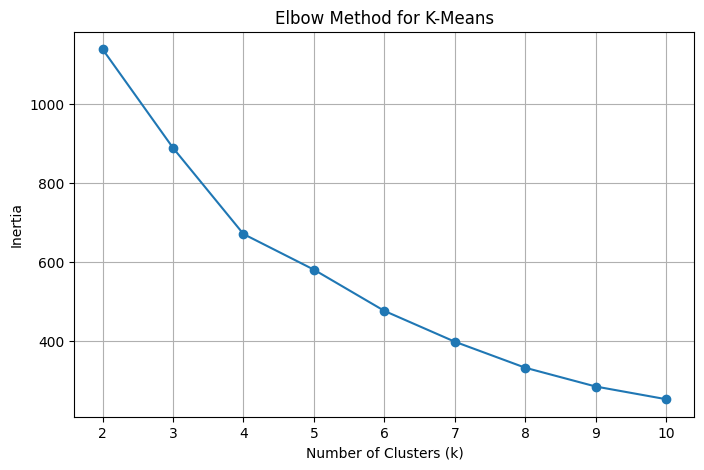

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker='o'
)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means')
plt.xticks(K)
plt.grid(True)

plt.show()

8.1.2 Silhouette calculation

In [ ]:
silhouette_scores = []

K = range(2, 11)

for k in K:

    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans_test.fit_predict(X_pca_4)

    score = silhouette_score(
        X_pca_4,
        labels
    )

    silhouette_scores.append(score)

    print(f"k = {k}: {score:.3f}")

k = 2: 0.305
k = 3: 0.309
k = 4: 0.358
k = 5: 0.321
k = 6: 0.368
k = 7: 0.356
k = 8: 0.341
k = 9: 0.344
k = 10: 0.327


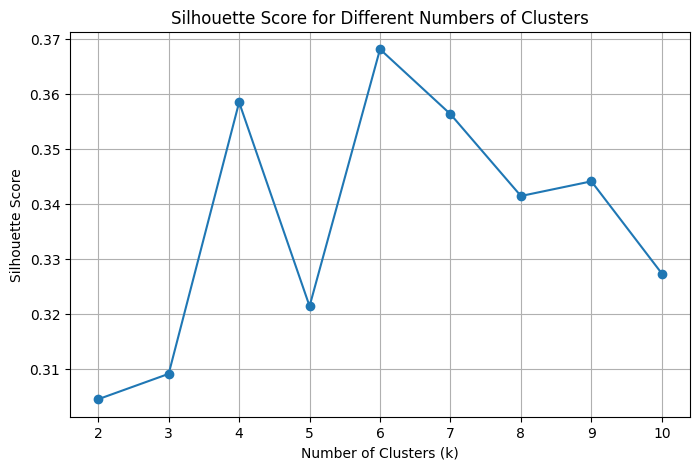

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    K,
    silhouette_scores,
    marker='o'
)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different Numbers of Clusters')
plt.xticks(K)
plt.grid(True)

plt.show()

8.2 Final K-Means Model

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

model_data['cluster'] = kmeans.fit_predict(X_pca_4)

8.3 Cluster Analysis and Interpretation

8.3.1 Cluster Profiles

In [ ]:
# Count the number of subzones in each cluster
cluster_sizes = (
    model_data['cluster']
    .value_counts()
    .sort_index()
)

cluster_sizes

,count
cluster,
0,83
1,20
2,105
3,24


In [ ]:
# Calculate the average characteristics of each cluster
cluster_profile = model_data.groupby('cluster')[
    cluster_features
].mean().round(2)


In [ ]:
# Add cluster size to the summary table
cluster_profile.insert(
    0,
    'number_of_subzones',
    cluster_sizes
)

cluster_profile

,number_of_subzones,senior_65_plus,senior_percentage,wifi_count,cc_count,library_count,distance_to_nearest_wifi,distance_to_nearest_cc,distance_to_nearest_library
cluster,,,,,,,,,
0,83,4513.01,17.22,10.11,1.13,0.00,153.11,370.35,1394.69
1,20,506.00,14.38,1.55,0.00,0.00,1328.88,2302.14,3364.95
2,105,1187.33,17.00,2.52,0.09,0.00,371.53,881.01,1387.11
3,24,4397.08,16.02,15.62,0.83,1.04,176.52,505.76,384.52


8.3.2 Top Subzones by Senior Population Within Each Cluster

In [ ]:
for cluster in sorted(model_data['cluster'].unique()):

    print(f"\nCluster {cluster}")

    display(
        model_data[
            model_data['cluster'] == cluster
        ][
            ['subzone',
             'planning_area',
             'senior_65_plus',
             'senior_percentage']
        ]
        .sort_values('senior_65_plus', ascending=False)
        .head(10)
    )


Cluster 0


,subzone,planning_area,senior_65_plus,senior_percentage
127,TAMPINES WEST,TAMPINES,11220.0,14.083093
109,BEDOK SOUTH,BEDOK,10190.0,21.824802
197,HONG KAH,JURONG WEST,9400.0,17.442939
222,YISHUN WEST,YISHUN,8780.0,16.286403
195,YUNNAN,JURONG WEST,8260.0,12.237037
201,WOODLANDS EAST,WOODLANDS,8200.0,8.284502
113,SERANGOON GARDEN,SERANGOON,8120.0,22.505543
170,HOUGANG WEST,HOUGANG,8070.0,17.751870
101,KEMBANGAN,BEDOK,7880.0,21.035771
123,BENDEMEER,KALLANG,7520.0,20.015970



Cluster 1


,subzone,planning_area,senior_65_plus,senior_percentage
69,HOLLAND ROAD,BUKIT TIMAH,1540.0,14.206642
191,TAGORE,ANG MO KIO,1510.0,18.993711
138,HILLCREST,BUKIT TIMAH,1460.0,15.417107
100,CORONATION ROAD,BUKIT TIMAH,1110.0,16.591928
105,SWISS CLUB,BUKIT TIMAH,920.0,17.228464
160,LOWER SELETAR,YISHUN,890.0,4.769561
208,SPRINGLEAF,YISHUN,780.0,17.848970
132,NATURE RESERVE,BUKIT PANJANG,500.0,12.987013
115,LOYANG EAST,PASIR RIS,360.0,16.822430
106,XILIN,TAMPINES,220.0,12.500000



Cluster 2


,subzone,planning_area,senior_65_plus,senior_percentage
111,KOVAN,HOUGANG,4090.0,16.485288
172,PENG SIANG,CHOA CHU KANG,3930.0,11.319124
180,YEW TEE,CHOA CHU KANG,3890.0,9.631097
171,BANGKIT,BUKIT PANJANG,3730.0,16.748990
149,YUHUA WEST,JURONG EAST,3530.0,18.423800
154,TOA PAYOH WEST,TOA PAYOH,3460.0,24.094708
21,TELOK BLANGAH RISE,BUKIT MERAH,3310.0,27.242798
41,CLEMENTI WOODS,CLEMENTI,3230.0,20.187500
147,UPPER PAYA LEBAR,SERANGOON,2990.0,17.671395
5,TIONG BAHRU STATION,BUKIT MERAH,2820.0,18.650794



Cluster 3


,subzone,planning_area,senior_65_plus,senior_percentage
133,TAMPINES EAST,TAMPINES,20200.0,15.422202
66,BEDOK NORTH,BEDOK,16700.0,20.405670
213,ALJUNIED,GEYLANG,7820.0,19.554889
158,JURONG WEST CENTRAL,JURONG WEST,6660.0,10.445420
176,SENGKANG TOWN CENTRE,SENGKANG,6330.0,10.244376
99,MARINE PARADE,MARINE PARADE,5900.0,21.949405
126,BISHAN EAST,BISHAN,5530.0,19.533734
67,TOA PAYOH CENTRAL,TOA PAYOH,5140.0,18.344040
125,SERANGOON CENTRAL,SERANGOON,5090.0,20.557351
121,JELEBU,BUKIT PANJANG,4570.0,14.595976


8.4 Cluster Visualisation

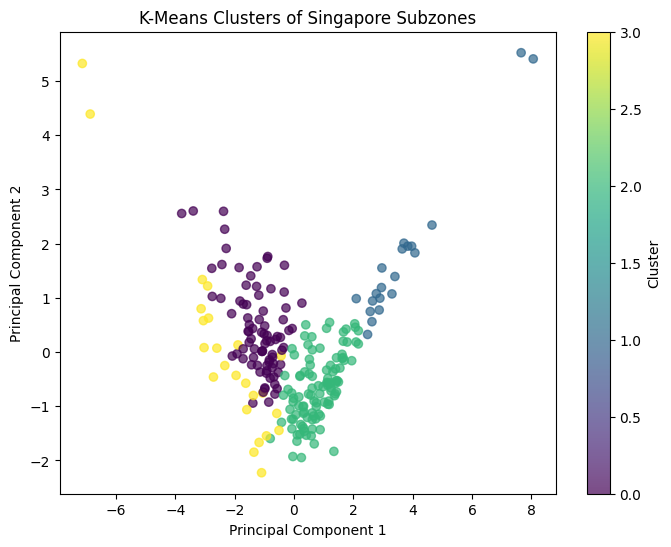

In [ ]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    model_data['PC1'],
    model_data['PC2'],
    c=model_data['cluster'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters of Singapore Subzones')

plt.colorbar(scatter, label='Cluster')

plt.show()

8.5 Geographic Distribution of Clusters

In [ ]:
cluster_map = pop_geo.merge(
    model_data[['subzone', 'cluster']],
    on='subzone',
    how='left'
)

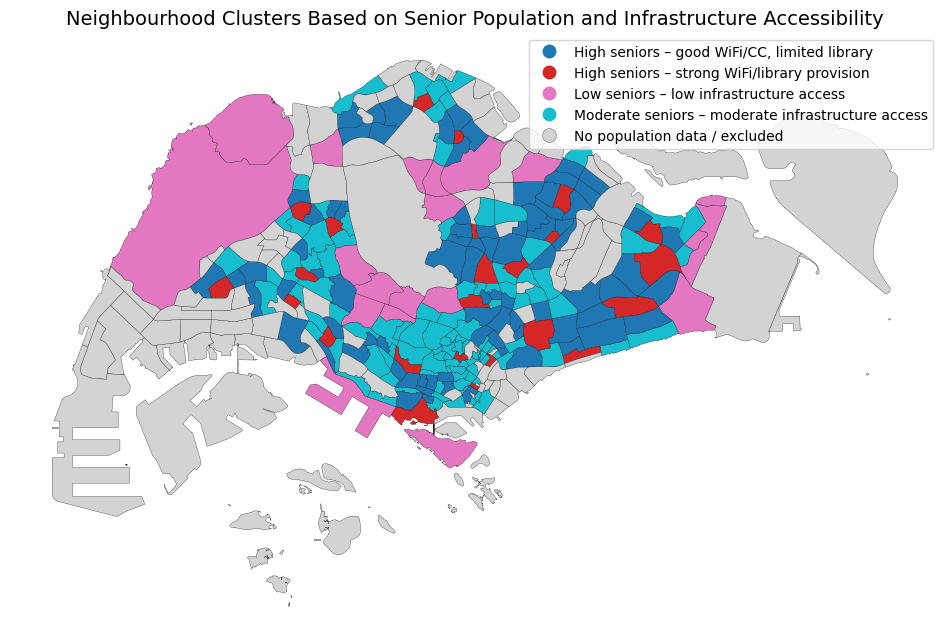

In [ ]:
# Give each cluster a meaningful name
cluster_labels = {
    0: 'High seniors – good WiFi/CC, limited library',
    1: 'Low seniors – low infrastructure access',
    2: 'Moderate seniors – moderate infrastructure access',
    3: 'High seniors – strong WiFi/library provision'
}

# Add the cluster names to the map
cluster_map['cluster_name'] = cluster_map['cluster'].map(cluster_labels)

# Plot the map
fig, ax = plt.subplots(figsize=(12, 10))

cluster_map.plot(
    column='cluster_name',
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor='black',
    linewidth=0.2,
    missing_kwds={
        'color': 'lightgrey',
        'label': 'No population data / excluded'
    }
)

ax.set_title(
    'Neighbourhood Clusters Based on Senior Population and Infrastructure Accessibility',
    fontsize=14
)

ax.axis('off')

plt.show()

9. Sensitivity Analysis: K-Means without PCA

9.1 Selecting the number of Clusters without PCA

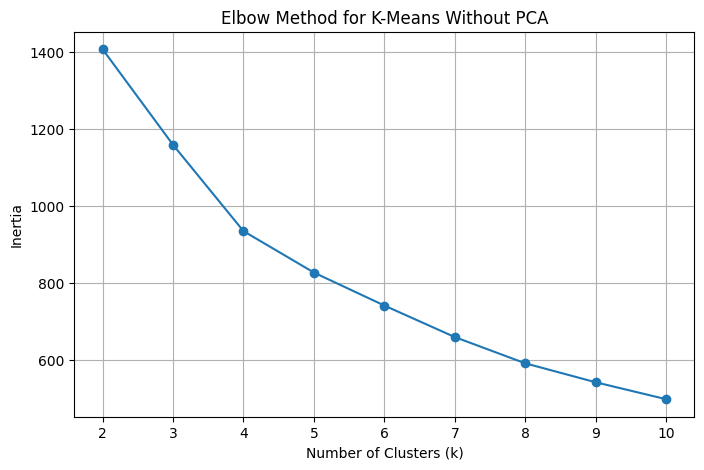

In [ ]:
# Elbow Method - K-Means without PCA

inertia_no_pca = []
K = range(2, 11)

for k in K:
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_test.fit(X_scaled)
    inertia_no_pca.append(kmeans_test.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia_no_pca,
    marker='o'
)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means Without PCA')
plt.xticks(K)
plt.grid(True)

plt.show()

In [ ]:
# Silhouette Analysis - K-Means without PCA

silhouette_scores_no_pca = []

for k in K:

    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans_test.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores_no_pca.append(score)

    print(f"k = {k}: {score:.3f}")

k = 2: 0.256
k = 3: 0.253
k = 4: 0.287
k = 5: 0.303
k = 6: 0.255
k = 7: 0.278
k = 8: 0.272
k = 9: 0.267
k = 10: 0.240


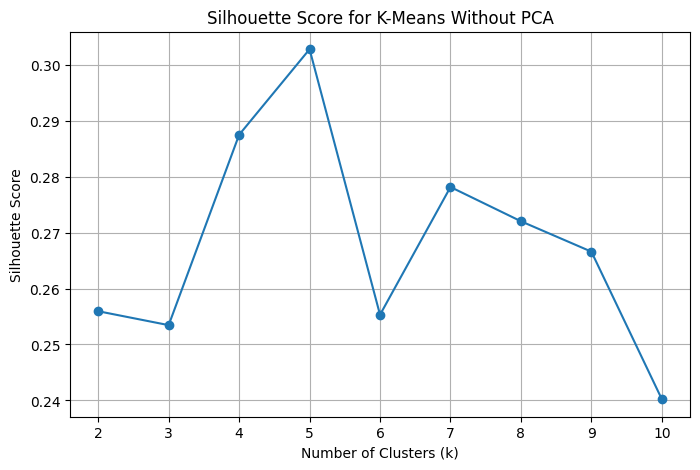

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    K,
    silhouette_scores_no_pca,
    marker='o'
)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for K-Means Without PCA')
plt.xticks(K)
plt.grid(True)

plt.show()

9.2 K-Means Clustering Without PCA

In [ ]:
kmeans_no_pca = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

model_data['cluster_no_pca'] = kmeans_no_pca.fit_predict(X_scaled)

In [ ]:
model_data['cluster_no_pca'].value_counts().sort_index()

,count
cluster_no_pca,
0,84
1,104
2,24
3,20


In [ ]:
cluster_profile_no_pca = model_data.groupby('cluster_no_pca')[
    cluster_features
].mean().round(2)

cluster_profile_no_pca

,senior_65_plus,senior_percentage,wifi_count,cc_count,library_count,distance_to_nearest_wifi,distance_to_nearest_cc,distance_to_nearest_library
cluster_no_pca,,,,,,,,
0,4416.90,17.22,10.00,1.14,0.00,156.29,366.54,1380.33
1,1232.98,16.99,2.54,0.07,0.00,371.05,888.99,1398.63
2,4397.08,16.02,15.62,0.83,1.04,176.52,505.76,384.52
3,506.00,14.38,1.55,0.00,0.00,1328.88,2302.14,3364.95


9.3 Comparison With PCA-Based Clustering

In [ ]:
pd.crosstab(
    model_data['cluster'],
    model_data['cluster_no_pca'],
    rownames=['With PCA'],
    colnames=['Without PCA']
)

Without PCA,0,1,2,3
With PCA,,,,
0,82,1,0,0
1,0,0,0,20
2,2,103,0,0
3,0,0,24,0


The clustering results without PCA showed broadly similar neighbourhood profiles to the PCA-based model. However, the PCA-based k=4 solution achieved a higher silhouette score (approximately 0.358) than the model without PCA (0.287), indicating better cluster separation. PCA was therefore retained for the final model